In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

In [2]:
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metadata_path = PROCESSED_DIR / "metadata.csv"

df = pd.read_csv(metadata_path)

In [3]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("CUDA GPU unavailable. Training will use CPU.")

PyTorch version: 2.7.1+cu128
Selected device: cuda
GPU: NVIDIA GeForce GTX 1650
CUDA version: 12.8
GPU memory: 4.0 GB


In [4]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dataset preparation and splitting

In [5]:
FEATURE_DIR = PROCESSED_DIR / "features"

train_actors = pd.read_csv(
    FEATURE_DIR / "train_actors.csv"
).squeeze("columns")

test_actors = pd.read_csv(
    FEATURE_DIR / "test_actors.csv"
).squeeze("columns")

train_actor_ids = set(train_actors.unique())
test_actor_ids = set(test_actors.unique())

print("Training actors:", sorted(train_actor_ids))
print("Testing actors:", sorted(test_actor_ids))

Training actors: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Testing actors: [np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]


In [6]:
train_pool = df[
    df["actor_id"].isin(train_actor_ids)
].copy()

test_df = df[
    df["actor_id"].isin(test_actor_ids)
].copy()

In [7]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_pool,
        groups=train_pool["actor_id"]
    )
)

train_df = train_pool.iloc[train_idx].copy()
val_df = train_pool.iloc[val_idx].copy()

print("Training recordings:", len(train_df))
print("Validation recordings:", len(val_df))
print("Testing recordings:", len(test_df))

Training recordings: 900
Validation recordings: 240
Testing recordings: 300


In [8]:
emotion_classes = sorted(df["emotion_label"].unique())

emotion_to_id = {
    emotion: index
    for index, emotion in enumerate(emotion_classes)
}

id_to_emotion = {
    index: emotion
    for emotion, index in emotion_to_id.items()
}

NUM_CLASSES = len(emotion_classes)

print("Emotion mapping:", emotion_to_id)
print("Number of classes:", NUM_CLASSES)

Emotion mapping: {'Angry': 0, 'Calm': 1, 'Disgust': 2, 'Fearful': 3, 'Happy': 4, 'Neutral': 5, 'Sad': 6, 'Surprised': 7}
Number of classes: 8


In [9]:
for dataset in [train_df, val_df, test_df]:

    dataset["label"] = dataset["emotion_label"].map(
        emotion_to_id
    )

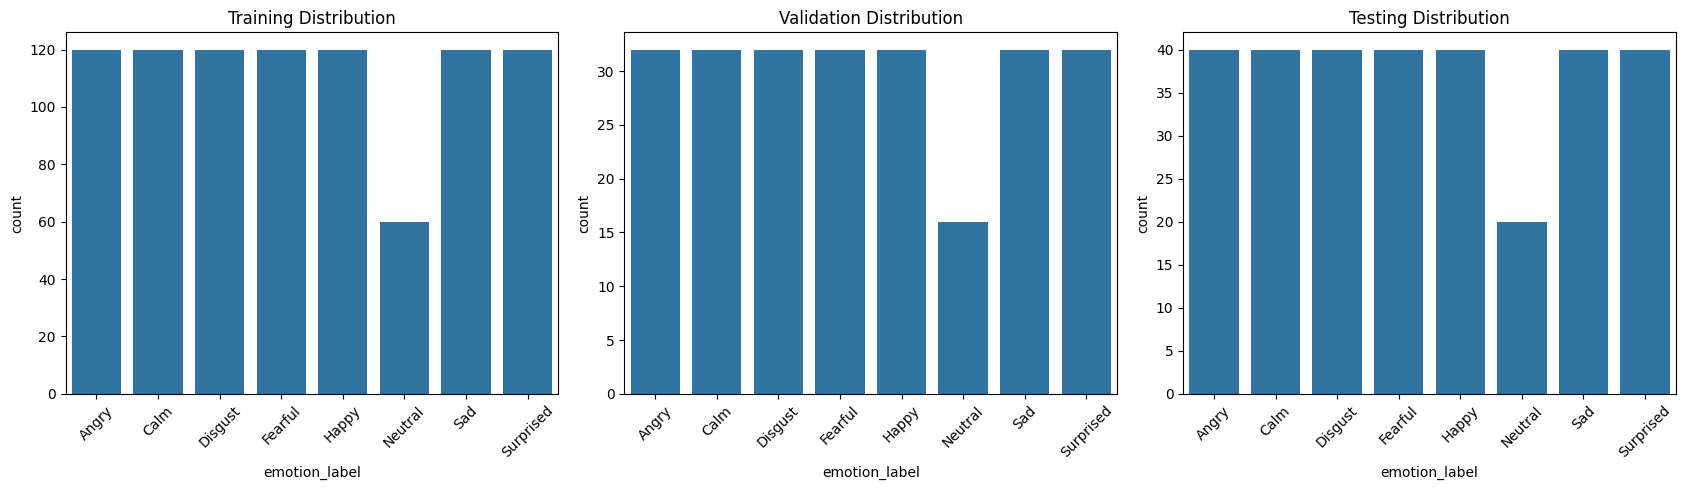

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, dataset) in zip(
    axes,
    [
        ("Training", train_df),
        ("Validation", val_df),
        ("Testing", test_df)
    ]
):

    sns.countplot(
        data=dataset,
        x="emotion_label",
        order=emotion_classes,
        ax=ax
    )

    ax.set_title(f"{name} Distribution")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [12]:
import joblib

split_dir = PROCESSED_DIR / "cnn_splits"
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train_metadata.csv", index=False)
val_df.to_csv(split_dir / "validation_metadata.csv", index=False)
test_df.to_csv(split_dir / "test_metadata.csv", index=False)

joblib.dump(
    emotion_to_id,
    MODEL_DIR / "emotion_to_id.pkl"
)

joblib.dump(
    id_to_emotion,
    MODEL_DIR / "id_to_emotion.pkl"
)

['Y:\\Python\\AI ML\\Month 2\\week 8-NLP\\49 — SPEECH EMOTION RECOGNITION\\models\\id_to_emotion.pkl']

In [13]:
TARGET_SR = 16000
DURATION = 4

TARGET_LENGTH = TARGET_SR * DURATION

N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 128

FMIN = 50
FMAX = 7600

In [14]:
def preprocess_audio(file_path):

    audio, original_sr = sf.read(file_path)

    # Convert stereo to mono
    if audio.ndim == 2:
        audio = np.mean(audio, axis=1)

    # Resample to 16 kHz
    if original_sr != TARGET_SR:
        audio = librosa.resample(
            y=audio,
            orig_sr=original_sr,
            target_sr=TARGET_SR
        )

    # Convert to fixed 4-second duration
    audio = librosa.util.fix_length(
        audio,
        size=TARGET_LENGTH
    )

    return audio.astype(np.float32)

In [16]:
def extract_log_mel(audio):

    mel_spectrogram = librosa.feature.melspectrogram(
        y=audio,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel_spectrogram,
        ref=1.0,
        top_db=80
    )

    return log_mel.astype(np.float32)

In [17]:
sample_path = train_df.iloc[0]["file_path"]

audio = preprocess_audio(sample_path)

log_mel = extract_log_mel(audio)

print("Audio shape:", audio.shape)
print("Log-Mel shape:", log_mel.shape)
print("Data type:", log_mel.dtype)

Audio shape: (64000,)
Log-Mel shape: (128, 251)
Data type: float32


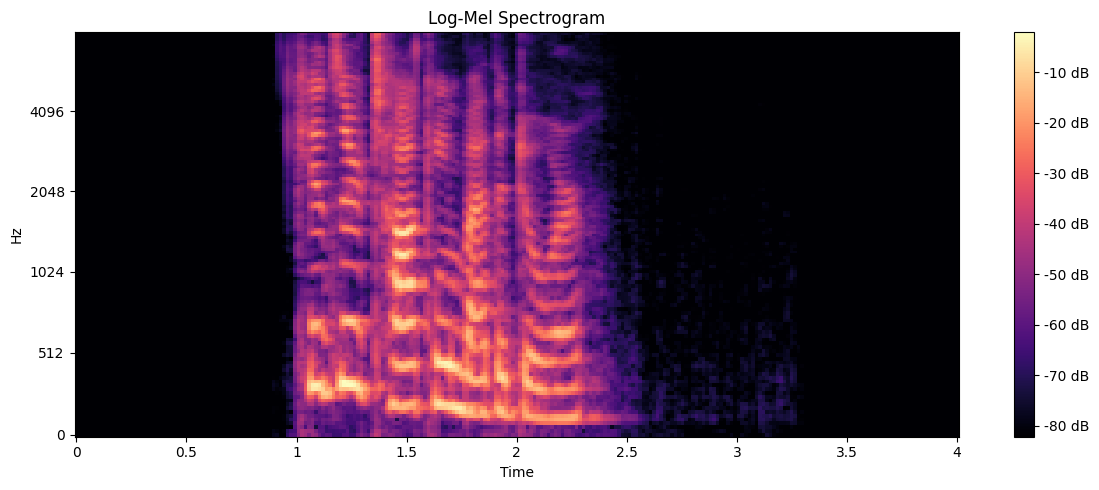

In [18]:
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    log_mel,
    sr=TARGET_SR,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    cmap="magma"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Mel Spectrogram")
plt.tight_layout()
plt.show()

# Custom Dataset and DataLoader.

In [19]:
CNN_FEATURE_DIR = PROCESSED_DIR / "cnn_features"
CNN_FEATURE_DIR.mkdir(parents=True, exist_ok=True)

def create_spectrogram_cache(dataset_df, split_name):

    output_path = CNN_FEATURE_DIR / f"{split_name}_logmel.npy"

    expected_frames = 1 + TARGET_LENGTH // HOP_LENGTH

    spectrograms = np.empty(
        (len(dataset_df), N_MELS, expected_frames),
        dtype=np.float32
    )

    for index, row in enumerate(dataset_df.itertuples()):

        audio = preprocess_audio(row.file_path)
        log_mel = extract_log_mel(audio)

        spectrograms[index] = log_mel

        if (index + 1) % 100 == 0:
            print(f"{split_name}: {index + 1}/{len(dataset_df)}")

    np.save(output_path, spectrograms)

    print(f"Saved {split_name} spectrograms:", spectrograms.shape)

    return output_path

In [20]:
train_cache_path = create_spectrogram_cache(train_df, "train")
val_cache_path = create_spectrogram_cache(val_df, "validation")
test_cache_path = create_spectrogram_cache(test_df, "test")

train: 100/900
train: 200/900
train: 300/900
train: 400/900
train: 500/900
train: 600/900
train: 700/900
train: 800/900
train: 900/900
Saved train spectrograms: (900, 128, 251)
validation: 100/240
validation: 200/240
Saved validation spectrograms: (240, 128, 251)
test: 100/300
test: 200/300
test: 300/300
Saved test spectrograms: (300, 128, 251)


In [21]:
train_logmels = np.load(train_cache_path, mmap_mode="r")
val_logmels = np.load(val_cache_path, mmap_mode="r")
test_logmels = np.load(test_cache_path, mmap_mode="r")

print("Training:", train_logmels.shape)
print("Validation:", val_logmels.shape)
print("Testing:", test_logmels.shape)

Training: (900, 128, 251)
Validation: (240, 128, 251)
Testing: (300, 128, 251)


In [22]:
logmel_mean = float(np.mean(train_logmels, dtype=np.float64))
logmel_std = float(np.std(train_logmels, dtype=np.float64))

print("Training Log-Mel mean:", logmel_mean)
print("Training Log-Mel standard deviation:", logmel_std)

Training Log-Mel mean: -58.89479821139731
Training Log-Mel standard deviation: 20.37776941738392


In [23]:
normalization_stats = {
    "mean": logmel_mean,
    "std": logmel_std
}

joblib.dump(
    normalization_stats,
    MODEL_DIR / "logmel_normalization.pkl"
)

['Y:\\Python\\AI ML\\Month 2\\week 8-NLP\\49 — SPEECH EMOTION RECOGNITION\\models\\logmel_normalization.pkl']

In [24]:
class SpeechEmotionDataset(Dataset):

    def __init__(self, spectrograms, labels, mean, std):

        self.spectrograms = spectrograms
        self.labels = np.asarray(labels, dtype=np.int64)

        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        # Load one spectrogram
        spectrogram = np.array(
            self.spectrograms[index],
            dtype=np.float32,
            copy=True
        )

        # Normalize using training statistics
        spectrogram = (spectrogram - self.mean) / (self.std + 1e-8)

        # Add channel dimension: (1, 128, 251)
        spectrogram = torch.from_numpy(spectrogram).unsqueeze(0)

        label = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return spectrogram, label

In [25]:
train_dataset = SpeechEmotionDataset(
    train_logmels,
    train_df["label"].values,
    logmel_mean,
    logmel_std
)

val_dataset = SpeechEmotionDataset(
    val_logmels,
    val_df["label"].values,
    logmel_mean,
    logmel_std
)

test_dataset = SpeechEmotionDataset(
    test_logmels,
    test_df["label"].values,
    logmel_mean,
    logmel_std
)

In [26]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [27]:
audio_batch, label_batch = next(iter(train_loader))

print("Audio batch shape:", audio_batch.shape)
print("Label batch shape:", label_batch.shape)

print("Audio tensor dtype:", audio_batch.dtype)
print("Label tensor dtype:", label_batch.dtype)

Audio batch shape: torch.Size([32, 1, 128, 251])
Label batch shape: torch.Size([32])
Audio tensor dtype: torch.float32
Label tensor dtype: torch.int64


# CNN Architecture

In [28]:
class EmotionCNN(nn.Module):

    def __init__(self, num_classes=8):

        super().__init__()

        self.features = nn.Sequential(

            # Convolution block 1
            nn.Conv2d(
                1, 32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution block 2
            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution block 3
            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution block 4
            nn.Conv2d(
                128, 256,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 8))
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 4 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [29]:
model = EmotionCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)

EmotionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

In [30]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

Total parameters: 2520136
Trainable parameters: 2520136


In [31]:
sample_batch, sample_labels = next(iter(train_loader))

sample_batch = sample_batch.to(DEVICE)

with torch.no_grad():

    output = model(sample_batch)

print("Input shape:", sample_batch.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([32, 1, 128, 251])
Output shape: torch.Size([32, 8])


# CNN Training Configuration

In [32]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [33]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

In [34]:
EPOCHS = 50
PATIENCE = 8

best_val_loss = float("inf")
early_stop_counter = 0

CHECKPOINT_PATH = MODEL_DIR / "best_cnn_model.pth"

In [35]:
if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    print("Training on:", torch.cuda.get_device_name(0))
    print(
        "Allocated GPU memory:",
        round(torch.cuda.memory_allocated() / 1024**2, 2),
        "MB"
    )
else:
    print("Training on CPU")

Training on: NVIDIA GeForce GTX 1650
Allocated GPU memory: 21.67 MB


In [40]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for inputs, labels in progress_bar:

        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        batch_size = inputs.size(0)

        running_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += batch_size

        progress_bar.set_postfix({
            "loss": f"{loss.item():.4f}",
            "accuracy": f"{correct / total:.4f}"
        })

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [41]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for inputs, labels in progress_bar:

            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            batch_size = inputs.size(0)

            running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += batch_size

            progress_bar.set_postfix({
                "loss": f"{loss.item():.4f}",
                "accuracy": f"{correct / total:.4f}"
            })

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

# CNN Training with tqdm

In [42]:
from tqdm.auto import tqdm

In [43]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
early_stop_counter = 0

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    # Validation
    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    # Learning rate adjustment
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # Store metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    print(f"Learning Rate: {current_lr:.6f}")

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        early_stop_counter = 0

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

        print("Best model checkpoint saved!")

    else:

        early_stop_counter += 1

    # Early stopping
    if early_stop_counter >= PATIENCE:

        print("Early stopping triggered!")
        break

print("\nCNN training completed!")


Epoch 1/50


Training:   0%|          | 0/29 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

Train Loss: 2.0031 | Train Accuracy: 0.2456
Val Loss: 1.7585 | Val Accuracy: 0.3333
Learning Rate: 0.001000
Best model checkpoint saved!

Epoch 2/50


Training:   0%|          | 0/29 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Train Loss: 0.9444 | Train Accuracy: 0.6422
Val Loss: 1.4884 | Val Accuracy: 0.4958
Learning Rate: 0.000250

Epoch 21/50


Training:   0%|          | 0/29 [00:00<?, ?it/s]

Validation:   0%|          | 0/8 [00:00<?, ?it/s]

Train Loss: 0.9353 | Train Accuracy: 0.6411
Val Loss: 1.4164 | Val Accuracy: 0.5167
Learning Rate: 0.000125
Early stopping triggered!

CNN training completed!


In [44]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULTS_DIR / "cnn_training_history.csv",
    index=False
)

print(history_df.tail())

    train_loss  train_accuracy  val_loss  val_accuracy
16    1.055860        0.600000  1.416315      0.504167
17    0.987362        0.641111  1.420558      0.512500
18    0.976690        0.644444  1.414674      0.508333
19    0.944433        0.642222  1.488356      0.495833
20    0.935307        0.641111  1.416403      0.516667


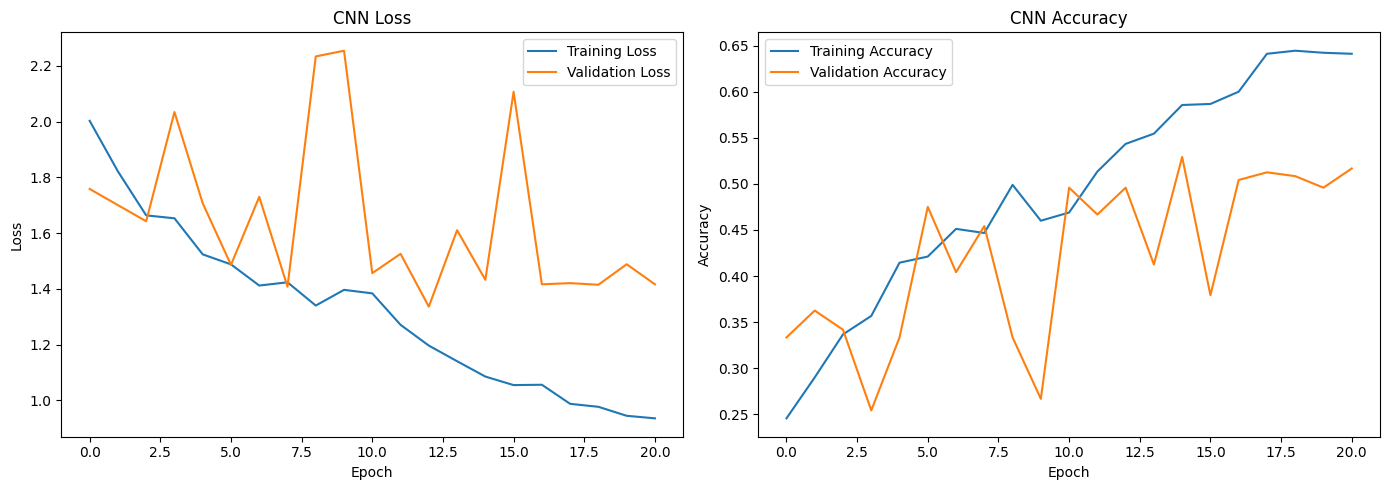

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(
    history["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("CNN Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy curves
axes[1].plot(
    history["train_accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("CNN Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [46]:
model.load_state_dict(
    torch.load(CHECKPOINT_PATH, map_location=DEVICE)
)

model.to(DEVICE)
model.eval()

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [47]:
from tqdm.auto import tqdm

y_true = []
y_pred = []
y_prob = []

model.eval()

with torch.inference_mode():

    for inputs, labels in tqdm(test_loader, desc="Testing CNN"):

        inputs = inputs.to(DEVICE)
        outputs = model(inputs)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Test predictions completed!")

Testing CNN:   0%|          | 0/10 [00:00<?, ?it/s]

Test predictions completed!


In [48]:
from sklearn.metrics import classification_report, accuracy_score

test_accuracy = accuracy_score(y_true, y_pred)

report = classification_report(
    y_true,
    y_pred,
    target_names=emotion_classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print(f"Test Accuracy: {test_accuracy:.4f}")
display(report_df.round(3))

Test Accuracy: 0.4400


,precision,recall,f1-score,support
Angry,0.882,0.375,0.526,40.00
Calm,0.358,0.950,0.521,40.00
Disgust,0.579,0.550,0.564,40.00
Fearful,0.643,0.225,0.333,40.00
Happy,0.294,0.375,0.330,40.00
Neutral,0.450,0.450,0.450,20.00
Sad,0.211,0.100,0.136,40.00
Surprised,0.571,0.500,0.533,40.00
accuracy,0.440,0.440,0.440,0.44
macro avg,0.499,0.441,0.424,300.00


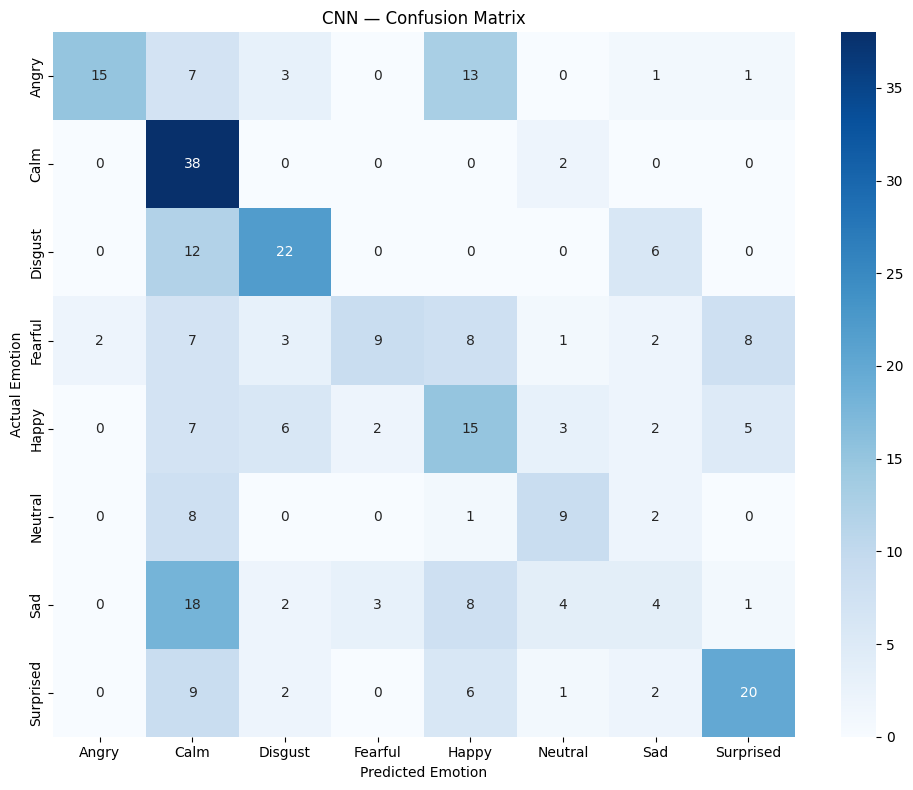

In [49]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_classes,
    yticklabels=emotion_classes
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("CNN — Confusion Matrix")
plt.tight_layout()
plt.show()

In [50]:
report_df.to_csv(
    RESULTS_DIR / "cnn_classification_report.csv"
)

pd.DataFrame(
    cm,
    index=emotion_classes,
    columns=emotion_classes
).to_csv(
    RESULTS_DIR / "cnn_confusion_matrix.csv"
)

predictions_df = pd.DataFrame({
    "actual_emotion": [id_to_emotion[i] for i in y_true],
    "predicted_emotion": [id_to_emotion[i] for i in y_pred],
    "confidence": y_prob.max(axis=1)
})

predictions_df.to_csv(
    RESULTS_DIR / "cnn_test_predictions.csv",
    index=False
)

print("CNN evaluation results saved!")

CNN evaluation results saved!


In [53]:
# Load Traditional ML evaluation report
traditional_report = pd.read_csv(
    RESULTS_DIR / "best_traditional_model_report.csv",
    index_col=0
)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Traditional ML", "CNN"],

    "Accuracy": [
        traditional_report.loc["accuracy"].iloc[0],
        test_accuracy
    ],

    "Macro F1": [
        traditional_report.loc["macro avg", "f1-score"],
        report_df.loc["macro avg", "f1-score"]
    ],

    "Weighted F1": [
        traditional_report.loc["weighted avg", "f1-score"],
        report_df.loc["weighted avg", "f1-score"]
    ]
})

display(comparison.round(4))

# Save comparison
comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

,Model,Accuracy,Macro F1,Weighted F1
0,Traditional ML,0.4967,0.4914,0.4971
1,CNN,0.4400,0.4241,0.4224


In [54]:
print("Traditional ML test actors:")
print(sorted(test_actors.unique()))

print("\nCNN test actors:")
print(sorted(test_df["actor_id"].unique()))

print(
    "\nSame test actors:",
    set(test_actors.unique()) == set(test_df["actor_id"].unique())
)

Traditional ML test actors:
[np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]

CNN test actors:
[np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]

Same test actors: True
